In [1]:
import torch 
import numpy as np 
import matplotlib.pyplot as plt 

from torch import nn
from tqdm import tqdm

In [2]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Usando dispositivo: {device}')

Usando dispositivo: cuda


In [3]:
# Carregando os dados simulados por diferenças finitas
dados = np.load('../Dados/Numericos/data_001.npz')

input = dados['input']
target = dados['target'].reshape(-1, 1)
param = dados['parameters']

data_total_size = input.shape[0]
print(f'Total de dados: {data_total_size}')

# Convertendo os dados para tensores do PyTorch
data_input_obs = torch.from_numpy(input).float().to(device)
data_target_obs = torch.from_numpy(target).float().to(device)
print(data_input_obs.shape, data_target_obs.shape)

Total de dados: 250000
torch.Size([250000, 3]) torch.Size([250000, 1])


In [4]:
# Definindo dados para condição inicial conhecida
data_input_ic = torch.from_numpy(input[:2500]).float().to(device)
data_target_ic = torch.from_numpy(target[:2500]).float().to(device)

In [5]:
# Definindo os pontos de colocation para o cálculo do resíduo da equação diferencial residual
collocation_points_size = 10_000
x = torch.FloatTensor(collocation_points_size).uniform_(0, 1)
y = torch.FloatTensor(collocation_points_size).uniform_(0, 1)
t = torch.FloatTensor(collocation_points_size).uniform_(0, 1)

collocation_points = torch.vstack([t, x, y]).T.requires_grad_(True).to(device)

In [6]:
# Inicializando o modelo de rede neural MLP 
model = nn.Sequential(
    nn.Linear(3, 256),   
    nn.Tanh(),
    nn.Linear(256, 256),
    nn.Tanh(),
    nn.Linear(256, 1)     
).to(device)

# Inicializando os parâmetros a serem aprendidos
log_D = nn.Parameter(torch.tensor(0.))
log_R = nn.Parameter(torch.tensor(0.))

In [7]:
def data_loss(model, data_input_obs, data_target_obs): 
    
    return torch.mean((model(data_input_obs) - data_target_obs)**2)

def residual_loss(model, pts, log_d, log_r):

    pts = pts.clone().requires_grad_(True)        
    u = model(pts)

    grads = torch.autograd.grad(u, pts, torch.ones_like(u), create_graph=True)[0]
    u_t, u_x, u_y = grads[:, 0], grads[:, 1], grads[:, 2]

    u_xx = torch.autograd.grad(u_x, pts, torch.ones_like(u_x), create_graph=True)[0][:, 0]
    u_yy = torch.autograd.grad(u_y, pts, torch.ones_like(u_y), create_graph=True)[0][:, 1]

    D = torch.exp(log_d)
    R = torch.exp(log_r)
    residual = u_t - D * (u_xx + u_yy) - R * u.squeeze(-1)
    return torch.mean(residual**2)

In [ ]:
epochs = 10_000

optim_model = torch.optim.AdamW(model.parameters(), lr = 1e-3)
optim_param = torch.optim.Adam([log_D, log_R], lr = 1e-2)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optim_param, T_max = epochs, eta_min=1e-6)

history = {'loss': [], 'data_loss': [], 'residual_loss': [], 'ic_loss': [], 'dl': [], 'rl': []}
for epoch in tqdm(range(epochs)):

    optim_model.zero_grad()
    optim_param.zero_grad()

    data_loss_value = data_loss(model, data_input_obs, data_target_obs)
    ic_loss_value = data_loss(model, data_input_ic, data_target_ic)
    residual_loss_value = residual_loss(model, collocation_points, log_D, log_R)
    loss = data_loss_value + ic_loss_value + residual_loss_value

    loss.backward()
    optim_model.step()
    optim_param.step()
    scheduler.step()

    history['loss'].append(loss.item())
    history['data_loss'].append(data_loss_value.item())
    history['residual_loss'].append(residual_loss_value.item())
    history['ic_loss'].append(ic_loss_value.item())
    history['dl'].append(torch.exp(log_D).item())
    history['rl'].append(torch.exp(log_R).item())

print('-' * 50)
print('\n')
d_estimado = torch.exp(log_D).item()
r_estimado = torch.exp(log_R).item()
d_ref, r_ref = param[0].item(), param[1].item()
print(f'D estimado: {d_estimado:.7f}\tR estimado: {r_estimado:.7f}')
print(f'D referência: {d_ref:.7f}\tR referência: {r_ref:.7f}')

erro_d = 1. - np.linalg.norm(d_estimado - param[0].item()) / np.linalg.norm(param[0].item())
erro_r = 1. - np.linalg.norm(r_estimado - param[1].item()) / np.linalg.norm(param[1].item())
print(f'Erro D: {erro_d:.2%}\tErro R: {erro_r:.2%}')

  0%|          | 0/10000 [00:00<?, ?it/s]c:\Users\rique\AppData\Local\Programs\Python\Python314\Lib\site-packages\torch\autograd\graph.py:882: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\cuda\CublasHandlePool.cpp:370.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
100%|██████████| 10000/10000 [07:51<00:00, 21.21it/s]

--------------------------------------------------


D estimado: 0.0007929	R estimado: 0.0221123
D referência: 0.0100000	R referência: 0.5000000
Erro D: 7.93%	Erro R: 4.42%


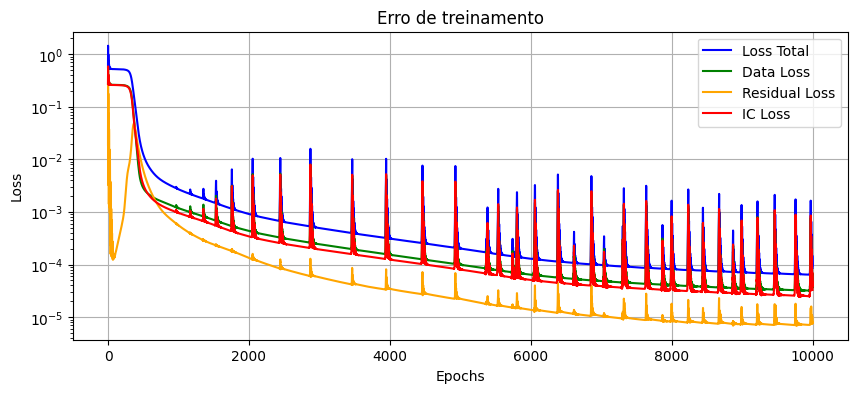

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(history['loss'], label='Loss Total', color='blue')
plt.plot(history['data_loss'], label='Data Loss', color='green')
plt.plot(history['residual_loss'], label='Residual Loss', color='orange')
plt.plot(history['ic_loss'], label='IC Loss', color='red')
plt.yscale('log')
plt.title('Erro de treinamento')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid()
plt.legend()
plt.show()

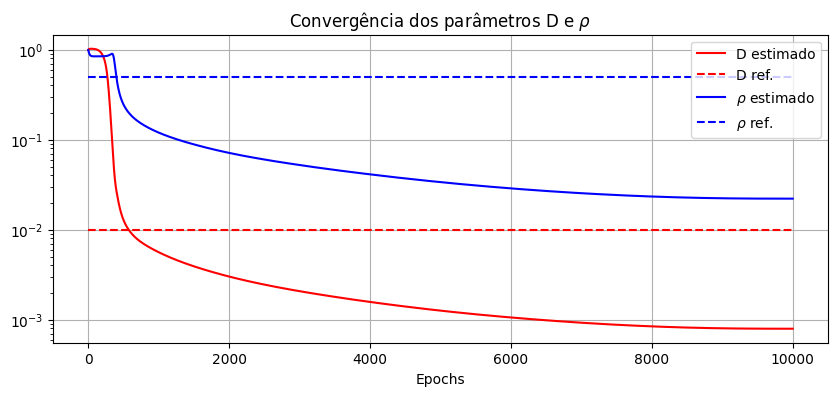

In [16]:
plt.figure(figsize=(10, 4))

plt.plot(history['dl'], label = r'D estimado', color = 'red')
plt.hlines(d_ref, 0, len(history['dl']), linestyles='dashed', label= r'D ref.', color = 'red')
plt.plot(history['rl'], label = r'$\rho$ estimado', color = 'blue')
plt.hlines(r_ref, 0, len(history['rl']), linestyles='dashed', label= r'$\rho$ ref.', color = 'blue')
plt.yscale('log')
plt.title(r'Convergência dos parâmetros D e $\rho$')
plt.xlabel('Epochs')
plt.grid()
plt.legend()
plt.show()